# Week 10 — Object Detection II (Checkpoint Resume Fix) | YCB-Video (BOP'19)
**Intern:** Mehrana Rezaei · **Group 1** · **Main Quest:** Convolutional Neural Networks  
**Side Quest:** Improving object detection: confidence thresholds, multiple objects, NMS, precision–recall and YOLO-style concepts

> **Experiment status:** This is an executable **Week 10 experimental notebook**, not a report of experiments already completed. Numerical conclusions and CSV files are generated only after running against the **actual retrained Week-09-compatible detector checkpoint and YCB-V images**. No Week 10 outcomes are fabricated.

### Question and hypothesis
Week 09's selected Faster R-CNN / MobileNetV3-FPN detector reached **validation five-class mAP50 = 0.6970** at epoch 4 (from the supplied Week 09 report). At confidence 0.50 it recorded **P = 0.5894, R = 0.8040**, with **bleach_cleanser recall = 0.14** and many `tomato_soup_can` / `master_chef_can` false positives. Can we improve *validation operating-point quality* by changing the **score threshold** and **class-aware NMS** without changing the network weights?

**Explicitly held constant during Week 10 tuning:** original 5 classes `[4,3,1,6,12]`, scene split, max 50 full frames/scene, `bbox_obj` fallback, 0.35 minimum visibility, 24-pixel minimum box side, backbone/head architecture and the **newly retrained baseline weights**. **Only inference settings change after retraining.**

### Deliverables generated after a real run
- Audit of all frame annotations and partial-label regions.
- Baseline vs controlled NMS×confidence comparisons; micro/macro precision, recall, F1, five-class AP50/mAP50, per-class curves.
- Multi-object vs single/empty-frame diagnostics; failure taxonomy and before/after example images.
- Frozen validation-only selection, one-time *optional* repeated-test evaluation, CSV/JSON/PNG and auto-filled technical report.

**Limitations:** this is an internal BOP'19 subset study, **not official BOP/COCO benchmark AP**. Test scenes 51 and 59 were already viewed in prior weeks. Also, the five-class labels are incomplete relative to the other YCB objects visible in each frame.

> **November 03 recovery update:** The earlier Colab run hit `Nonfinite training loss` at epoch 4, batch ~160/200 after epochs 1–3 completed. This revision disables FP16 autocast in training, trains in FP32 with batch size 1 by default, records non-finite batches and safely skips up to three bad batches per epoch, and resumes from `week10_training_progress.pth` when available. An alternative **`RECOVERY_POLICY = "best_only"`** evaluates the already-saved best checkpoint without any further training. Saving the Colab document and saving model checkpoints are separate operations. The previous failure may have other causes; FP32 is a mitigation, not a diagnosis.

> **Checkpoint-free edition:** The Week 09 weights were unavailable, so this notebook automatically trains a **new compatible Faster R-CNN baseline** from COCO-pretrained initialization. The original Week 09 scores in the report are historical context **only**, not reproducible by assumption. All Week 10 threshold/NMS comparisons use the same newly saved weights.


In [1]:
import os
from pathlib import Path
MODE = os.getenv('WEEK10_MODE', 'real').strip().lower()  # 'real' or 'selftest'
assert MODE in {'real','selftest'}
TRAIN_IF_MISSING = True          # Automatically train a new Week-09-compatible baseline.
SAVE_TO_GOOGLE_DRIVE = True      # Strongly recommended in Colab: checkpoint survives disconnect.
RUN_FINAL_TEST = False          # Hold test closed until validation settings are frozen.
ALLOW_DATA_DOWNLOAD = True
STRICT_WEEK09_DATA_MATCH = True

IS_COLAB = Path('/content').exists()
if MODE == 'real' and IS_COLAB and SAVE_TO_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RUN_ROOT = Path('/content/drive/MyDrive/AI_Internship_Group1/Week10')
else:
    RUN_ROOT = Path('/content/week10_retrained' if IS_COLAB else 'outputs/week10_retrained')

DATASET_ROOT = Path('/content/datasets/ycbv' if IS_COLAB else 'datasets/ycbv')
OUTPUT_DIR = RUN_ROOT / 'results'
CHECKPOINT_PATH = RUN_ROOT / 'checkpoints' / 'week10_retrained_week09_compatible_best.pth'
PROGRESS_PATH = RUN_ROOT / 'checkpoints' / 'week10_training_progress.pth'

SEED = 42
SELECTED_IDS = [4, 3, 1, 6, 12]
CLASS_NAMES = ['tomato_soup_can', 'sugar_box', 'master_chef_can', 'tuna_fish_can', 'bleach_cleanser']
LABEL_TO_NAME = {0:'background', **{i+1:name for i,name in enumerate(CLASS_NAMES)}}
OBJ_TO_LABEL = {obj_id:i+1 for i,obj_id in enumerate(SELECTED_IDS)}
NUM_CLASSES = 6
SCENES = {'train':[48,49,50,53,54,56,57,58], 'validation':[52,55], 'test':[51,59]}
MAX_FRAMES_PER_SCENE = 50
MIN_VISIBILITY = 0.35
MIN_BOX_SIDE = 24
MODEL_MIN_SIZE, MODEL_MAX_SIZE = 480, 640
AP_FLOOR, IOU_THRESHOLD = 0.05, 0.50
BASELINE_NMS, BASELINE_SCORE = 0.50, 0.50
NMS_GRID = [0.30, 0.50, 0.70]
SCORE_GRID = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
MAX_DETECTIONS = 100
BATCH_SIZE, NUM_WORKERS = 1, 0  # FP32 uses more memory; 1 is safer on Colab T4.
RETRAIN_EPOCHS = 8
TRAIN_WITH_AMP = False  # FP32 retry: avoids potential float16 overflow in detection loss.
MAX_SKIPPED_BAD_BATCHES = 3  # Fails explicitly if systematic numerical problems persist.
RECOVERY_POLICY = 'resume'  # 'resume' => epochs 4–8, or 'best_only' => evaluate saved best now.
assert RECOVERY_POLICY in ('resume','best_only')

assert len(set(sum(SCENES.values(), [])))==12
assert all(set(SCENES[a]).isdisjoint(SCENES[b]) for a,b in
           [('train','validation'),('train','test'),('validation','test')])
assert BASELINE_NMS in NMS_GRID and BASELINE_SCORE in SCORE_GRID
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CHECKPOINT_PATH.parent.mkdir(parents=True,exist_ok=True)
print('MODE:',MODE,'| pretrained detector retraining:',TRAIN_IF_MISSING)
print('Output:',OUTPUT_DIR,'| checkpoint:',CHECKPOINT_PATH)
print('No original Week 09 checkpoint is required. Test scenes do not select parameters.')
print('Recovery policy:',RECOVERY_POLICY,'| FP32 training:',not TRAIN_WITH_AMP,'| batch size:',BATCH_SIZE)


Mounted at /content/drive
MODE: real | pretrained detector retraining: True
Output: /content/drive/MyDrive/AI_Internship_Group1/Week10/results | checkpoint: /content/drive/MyDrive/AI_Internship_Group1/Week10/checkpoints/week10_retrained_week09_compatible_best.pth
No original Week 09 checkpoint is required. Test scenes do not select parameters.
Recovery policy: resume | FP32 training: True | batch size: 1


## B. Imports and environment check
No hidden install/setup magic: required packages are listed here, and missing optional dependencies are installed only in real mode. Use matching PyTorch/Torchvision versions in Colab.

In [2]:
import sys, subprocess, importlib.util
required = {'torch':'torch', 'torchvision':'torchvision', 'numpy':'numpy',
            'pandas':'pandas', 'matplotlib':'matplotlib', 'PIL':'pillow',
            'tqdm':'tqdm', 'huggingface_hub':'huggingface_hub'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing and MODE == 'real':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
elif missing:
    print('Self-test optional missing packages:', missing)

from collections import Counter, defaultdict
from datetime import datetime, timezone
import copy, hashlib, json, math, random, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from tqdm.auto import tqdm
import torch, torchvision
from torchvision.ops import box_iou, batched_nms
from torchvision.transforms import functional as TF
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Versions:', torch.__version__, torchvision.__version__, '| device:', DEVICE)

Versions: 2.11.0+cu130 0.26.0+cu130 | device: cuda


## C. Evaluation functions (based on Week 09, corrected to expose curves)

For each **class separately**, rank predictions by confidence across images, greedily match to **one unused GT box of the same class** when IoU ≥ 0.50. The internal **AP50** uses the area under an interpolated precision–recall envelope. **Operating-point** P/R/F1 uses the selected confidence cutoff. A threshold sweep changes P/R/F1; AP is computed from the fixed low score floor separately. This is not official COCO AP@[.50:.95].

In [3]:
def div0(num, den):
    return float(num / den) if den else 0.0

def match_one_class(predictions, targets, cls, score_threshold, iou_threshold=IOU_THRESHOLD):
    assert len(predictions) == len(targets), 'Prediction/GT frame count mismatch'
    ground_truth = {}
    used = {}
    proposals = []
    n_gt = 0
    for img_idx, (pred, gt) in enumerate(zip(predictions, targets)):
        gt_boxes = gt['boxes'][gt['labels'] == cls].float()
        ground_truth[img_idx] = gt_boxes
        used[img_idx] = set()
        n_gt += len(gt_boxes)
        kept = torch.where((pred['labels'] == cls) & (pred['scores'] >= score_threshold))[0]
        for index in kept.tolist():
            proposals.append((float(pred['scores'][index]), img_idx, index,
                              pred['boxes'][index].float()))
    proposals.sort(key=lambda row: (-row[0], row[1], row[2]))
    tp_seq, fp_seq, matched_ious, match_log = [], [], [], []
    for score, img_idx, pred_idx, predicted_box in proposals:
        boxes = ground_truth[img_idx]
        best_idx, best_iou = -1, 0.0
        if len(boxes):
            overlaps = box_iou(predicted_box.unsqueeze(0), boxes)[0]
            for candidate in torch.argsort(overlaps, descending=True).tolist():
                if candidate not in used[img_idx]:
                    best_idx, best_iou = candidate, float(overlaps[candidate])
                    break
        is_tp = best_idx >= 0 and best_iou >= iou_threshold
        if is_tp:
            used[img_idx].add(best_idx)
            matched_ious.append(best_iou)
        tp_seq.append(int(is_tp)); fp_seq.append(int(not is_tp))
        match_log.append({'image_index':img_idx, 'prediction_index':pred_idx,
                          'cls':cls, 'score':score, 'tp':int(is_tp), 'iou':best_iou})
    tp = sum(tp_seq)
    return {'tp':int(tp), 'fp':int(sum(fp_seq)), 'fn':int(n_gt-tp),
            'n_gt':int(n_gt), 'n_pred':len(proposals),
            'tp_seq':np.asarray(tp_seq, dtype=float),
            'fp_seq':np.asarray(fp_seq, dtype=float),
            'matched_ious':matched_ious, 'match_log':match_log}

def pr_sequence(matched):
    tp_seq, fp_seq = matched['tp_seq'], matched['fp_seq']
    if len(tp_seq) == 0:
        return np.array([0.]), np.array([1.])
    recall = np.cumsum(tp_seq) / max(matched['n_gt'], 1)
    precision = np.cumsum(tp_seq) / np.maximum(np.cumsum(tp_seq+fp_seq), 1)
    return np.r_[0., recall], np.r_[1., precision]

def ap50_from_matches(matched):
    if matched['n_gt'] == 0: return float('nan')
    if not len(matched['tp_seq']): return 0.0
    r, p = pr_sequence(matched)
    r = np.r_[r, 1.0]
    p = np.r_[p, 0.0]
    p = np.maximum.accumulate(p[::-1])[::-1]
    return float(np.sum((r[1:]-r[:-1]) * p[1:]))

def evaluate_detection(predictions, targets, score_threshold, iou_threshold=IOU_THRESHOLD):
    rows, all_ious = [], []
    for cls in range(1, NUM_CLASSES):
        matched = match_one_class(predictions, targets, cls, score_threshold, iou_threshold)
        ranked = match_one_class(predictions, targets, cls, AP_FLOOR, iou_threshold)
        p = div0(matched['tp'], matched['tp'] + matched['fp'])
        r = div0(matched['tp'], matched['tp'] + matched['fn'])
        f1 = div0(2*p*r, p+r)
        rows.append({'class_id':cls, 'class_name':LABEL_TO_NAME[cls],
                     'support':matched['n_gt'], 'predictions':matched['n_pred'],
                     'tp':matched['tp'], 'fp':matched['fp'], 'fn':matched['fn'],
                     'precision':p, 'recall':r, 'f1':f1,
                     'ap50':ap50_from_matches(ranked),
                     'mean_tp_iou':float(np.mean(matched['matched_ious']))
                                   if matched['matched_ious'] else np.nan})
        all_ious.extend(matched['matched_ious'])
    by_class = pd.DataFrame(rows)
    tp, fp, fn = (int(by_class[k].sum()) for k in ('tp','fp','fn'))
    prec, recall = div0(tp,tp+fp), div0(tp,tp+fn)
    supported = by_class[by_class['support'] > 0]  # subgroup metrics omit undefined empty-GT classes
    summary = {'score_threshold':float(score_threshold),
               'mAP50':float(by_class['ap50'].mean()),
               'micro_precision':prec, 'micro_recall':recall,
               'micro_f1':div0(2*prec*recall,prec+recall),
               'macro_f1':float(supported['f1'].mean()) if len(supported) else float('nan'),
               'macro_precision':float(supported['precision'].mean()) if len(supported) else float('nan'),
               'macro_recall':float(supported['recall'].mean()) if len(supported) else float('nan'),
               'tp':tp, 'fp':fp, 'fn':fn,
               'mean_tp_iou':float(np.mean(all_ious)) if all_ious else None,
               'frames':len(predictions)}
    return summary, by_class

### C1. Offline unit tests: matching, thresholds, duplicate predictions and YOLO-style class-aware NMS
These tests run in both modes; **perfect synthetic examples are not real performance results**.

In [4]:
# Boxes in an invented 100x100 image; repeated boxes intentionally test duplicate suppression.
sgt = [{'boxes':torch.tensor([[0.,0.,20.,20.],[40.,40.,60.,60.]]),
        'labels':torch.tensor([1,2])}]
spred = [{'boxes':torch.tensor([[0.,0.,20.,20.],[0.,0.,20.,20.],[40.,40.,60.,60.]]),
          'labels':torch.tensor([1,1,2]),'scores':torch.tensor([.99,.85,.97])}]
assert match_one_class(spred,sgt,1,.5)['tp'] == 1
assert match_one_class(spred,sgt,1,.5)['fp'] == 1
assert match_one_class(spred,sgt,1,.90)['fp'] == 0
assert math.isclose(ap50_from_matches(match_one_class(spred,sgt,1,AP_FLOOR)),1.0,abs_tol=1e-8)
# Same location, different classes: class-aware NMS must retain both.
boxes = torch.tensor([[0.,0.,20.,20.],[0.,0.,20.,20.],[0.,0.,20.,20.]])
conf = torch.tensor([.95,.90,.85]); labels = torch.tensor([1,1,2])
kept = batched_nms(boxes,conf,labels,0.5).tolist()
assert kept == [0,2], f'Class-aware NMS test failed: {kept}'
# IoU=0 for disjoint boxes, IoU=1 for identical boxes.
assert math.isclose(float(box_iou(boxes[:1],boxes[:1])[0,0]),1.0)
assert len(evaluate_detection(spred,sgt,.5)[1]) == 5
print('PASS: score threshold, one-to-one IoU, AP50 and class-aware NMS unit tests')
if MODE == 'selftest': print('SELFTEST ONLY: real YCB data, model inference and claims are intentionally skipped.')

PASS: score threshold, one-to-one IoU, AP50 and class-aware NMS unit tests


## D. Download/reuse YCB-V BOP'19 and build the **same** frame targets

The 12 scenes, deterministic frame selection, visibility filter and box clipping reproduce Week 09. The *extra* `ignored_regions` are **for audits only**; they are not training positives and **are not removed from standard FP metrics**. Nonselected objects and dropped positive annotations make this a partial-label problem.

In [5]:
if MODE == 'real':
    from huggingface_hub import hf_hub_download

    def read_json(path):
        return json.loads(Path(path).read_text(encoding='utf-8'))

    def dataset_ready(root):
        return all((root/'test'/f'{s:06d}'/'scene_gt.json').is_file()
                   and (root/'test'/f'{s:06d}'/'scene_gt_info.json').is_file()
                   for splits in SCENES.values() for s in splits)

    def extract_safe(zip_path, dest):
        dest.mkdir(parents=True, exist_ok=True)
        base = dest.resolve()
        with zipfile.ZipFile(zip_path) as z:
            for item in z.infolist():
                if not (base/item.filename).resolve().is_relative_to(base):
                    raise ValueError('Untrusted ZIP path: '+item.filename)
            z.extractall(base)

    if not dataset_ready(DATASET_ROOT):
        if not ALLOW_DATA_DOWNLOAD:
            raise FileNotFoundError('Missing YCB-V scene files at '+str(DATASET_ROOT))
        for name in ('ycbv_base.zip','ycbv_test_bop19.zip'):
            print('Downloading BOP archive:', name)
            archive = hf_hub_download(repo_id='bop-benchmark/ycbv',repo_type='dataset',filename=name)
            extract_safe(archive,DATASET_ROOT)
    assert dataset_ready(DATASET_ROOT)
    print('YCB-V ready:',DATASET_ROOT)

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

YCB-V ready: /content/datasets/ycbv


In [6]:
if MODE == 'real':
    def image_for(scene_dir, image_id):
        for ext in ('.png','.jpg','.jpeg'):
            path = scene_dir/'rgb'/f'{image_id:06d}{ext}'
            if path.exists(): return path
        raise FileNotFoundError(f'RGB missing: {scene_dir.name}/{image_id}')

    def choose_ids(ids, cap):
        ids = sorted(int(x) for x in ids)
        if cap is None or len(ids)<=cap: return ids
        positions = np.linspace(0,len(ids)-1,cap,dtype=int)
        return [ids[i] for i in sorted(set(positions.tolist()))]

    def clipped_box(raw, width, height):
        if raw is None: return None
        x,y,w,h = map(float,raw)
        coords = [max(0.,min(float(width),x)), max(0.,min(float(height),y)),
                  max(0.,min(float(width),x+w)),max(0.,min(float(height),y+h))]
        return coords if coords[2]-coords[0]>1 and coords[3]-coords[1]>1 else None

    def frame_table(split):
        records=[]
        for scene_id in SCENES[split]:
            folder=DATASET_ROOT/'test'/f'{scene_id:06d}'
            scene_gt=read_json(folder/'scene_gt.json')
            scene_info=read_json(folder/'scene_gt_info.json')
            for image_id in choose_ids(scene_gt.keys(),MAX_FRAMES_PER_SCENE):
                key=str(image_id)
                if key not in scene_gt: key=f'{image_id:06d}'
                objects, infos=scene_gt[key],scene_info[key]
                assert len(objects)==len(infos)
                path=image_for(folder,image_id)
                with Image.open(path) as im: width,height=im.size
                boxes,labels,ignored_regions=[],[],[]
                ignored_other=dropped_selected=0
                for obj, meta in zip(objects,infos):
                    oid=int(obj['obj_id'])
                    raw=meta.get('bbox_obj') or meta.get('bbox_visib')
                    box=clipped_box(raw,width,height)
                    if oid not in OBJ_TO_LABEL:
                        ignored_other+=1
                        if box: ignored_regions.append({'box':box,'obj_id':oid,'reason':'unselected_class'})
                        continue
                    visibility=float(meta.get('visib_fract',1.0))
                    # Test size BEFORE clipping, identical to the Week-09 code.
                    if (raw is None or visibility<MIN_VISIBILITY
                        or min(float(raw[2]),float(raw[3]))<MIN_BOX_SIDE or box is None):
                        dropped_selected+=1
                        if box: ignored_regions.append({'box':box,'obj_id':oid,'reason':'filtered_selected'})
                        continue
                    boxes.append(box); labels.append(OBJ_TO_LABEL[oid])
                records.append({'scene_id':scene_id,'im_id':image_id,'rgb_path':str(path),
                                'width':width,'height':height,'boxes':boxes,'labels':labels,
                                'ignored_other':ignored_other,'dropped_selected':dropped_selected,
                                'ignored_regions':ignored_regions})
        return records

    FRAME_RECORDS={split:frame_table(split) for split in SCENES}
    assert all(len(rows)>0 for rows in FRAME_RECORDS.values())
    assert all(len({(r['scene_id'],r['im_id']) for r in rows})==len(rows)
               for rows in FRAME_RECORDS.values())
    assert all(set(lab for r in rows for lab in r['labels'])==set(range(1,NUM_CLASSES))
               for rows in FRAME_RECORDS.values())

    summary_rows=[]
    for split,rows in FRAME_RECORDS.items():
        counts=Counter(lab for r in rows for lab in r['labels'])
        summary_rows.append({'split':split,'frames':len(rows),'target_boxes':sum(len(r['labels']) for r in rows),
                             'empty_target_frames':sum(not r['labels'] for r in rows),
                             'multi_target_frames':sum(len(r['labels'])>=2 for r in rows),
                             'other_ycb_instances':sum(r['ignored_other'] for r in rows),
                             'filtered_selected':sum(r['dropped_selected'] for r in rows),
                             **{LABEL_TO_NAME[c]:counts[c] for c in range(1,NUM_CLASSES)}})
    split_summary=pd.DataFrame(summary_rows)
    display(split_summary)
    # Historical counts recorded in the supplied Week-09 report. Stop if the input changed.
    expected_week09={'train':(400,584),'validation':(100,250),'test':(100,300)}
    for row in summary_rows:
        expected=expected_week09[row['split']]
        observed=(row['frames'],row['target_boxes'])
        if STRICT_WEEK09_DATA_MATCH and observed != expected:
            raise ValueError(f'Historical Week09 sample mismatch for {row["split"]}: '
                             f'expected (frames, selected boxes)={expected}; observed={observed}. '
                             'Check dataset version and frame sampling before comparing Week10.')
    split_summary.to_csv(OUTPUT_DIR/'split_summary.csv',index=False)
    # Hash stable annotations, independent of the original download location.
    ann_payload={split:[(r['scene_id'],r['im_id'],r['boxes'],r['labels']) for r in rows]
                 for split,rows in FRAME_RECORDS.items()}
    ANNOTATION_SHA256=hashlib.sha256(json.dumps(ann_payload,sort_keys=True).encode()).hexdigest()
    (OUTPUT_DIR/'frame_annotations.json').write_text(json.dumps(FRAME_RECORDS,indent=2),encoding='utf8')
    print('Annotation sha256:',ANNOTATION_SHA256)

,split,frames,target_boxes,empty_target_frames,multi_target_frames,other_ycb_instances,filtered_selected,tomato_soup_can,sugar_box,master_chef_can,tuna_fish_can,bleach_cleanser
0,train,400,584,16,200,1150,16,134,150,100,100,100
1,validation,100,250,0,50,200,0,50,50,50,50,50
2,test,100,300,0,100,250,0,100,50,50,50,50


Annotation sha256: 2f50246bb4787cc6d3b621151cfb679679629fb319b26ee3e2da01a8e5cff658


## E. Detector, checkpoint safety, and mandatory baseline retraining (first run)

The original Week 09 trained `.pth` file is missing. On the **first run**, this notebook initializes the same **Faster R-CNN / MobileNetV3-FPN** architecture from **COCO-pretrained** weights, replaces the classifier with the same **five YCB classes + background**, uses the same scene split and training hyperparameters, and saves the best checkpoint using **validation mAP50**. This is a **new baseline run**, **not** the original Week 09 weights. It will not necessarily reproduce the historical 0.6970 figure.

Once the new baseline is trained, **no weights are updated during the Week 10 comparison**: only confidence threshold and NMS settings change. On subsequent runs, the saved checkpoint is loaded without retraining.

A separate `week10_training_progress.pth` stores optimizer, scheduler, scaler and last completed epoch so an interrupted run can resume. Keep both files in Google Drive. Never load untrusted `.pth` checkpoint files.

**Recovery compatibility:** The original COCO-pretrained training run had
`trainable_backbone_layers=3`. This revision recreates the same frozen backbone
when loading without pretraining weights, making the saved AdamW parameter
group compatible. If external checkpoint metadata are incompatible, trained
model weights remain intact, while optimizer moments can be reset with a
visible warning.


In [7]:
if MODE == 'real':
    class YCBDetectionDataset(Dataset):
        def __init__(self,rows): self.rows=rows
        def __len__(self): return len(self.rows)
        def __getitem__(self,index):
            r=self.rows[index]
            with Image.open(r['rgb_path']) as raw: image=TF.to_tensor(raw.convert('RGB'))
            boxes=torch.tensor(r['boxes'],dtype=torch.float32).reshape(-1,4)
            labels=torch.tensor(r['labels'],dtype=torch.int64)
            assert boxes.shape[0]==labels.shape[0]
            assert all(1<=int(v)<NUM_CLASSES for v in labels)
            area=(boxes[:,2]-boxes[:,0])*(boxes[:,3]-boxes[:,1])
            target={'boxes':boxes,'labels':labels,'area':area,
                    'image_id':torch.tensor([index]),'iscrowd':torch.zeros(len(labels),dtype=torch.int64)}
            return image,target

    def collate(batch): return tuple(zip(*batch))

    def make_loader(split,batch_size=1):
        return DataLoader(YCBDetectionDataset(FRAME_RECORDS[split]),batch_size=batch_size,
                          shuffle=(split=='train'),num_workers=NUM_WORKERS,collate_fn=collate,
                          pin_memory=USE_AMP,
                          generator=torch.Generator().manual_seed(SEED) if split=='train' else None)

    def enforce_backbone_freeze(net, trainable_layers=3):
        """Reproduce torchvision MobileNetV3 stage freezing without downloading weights.

        torchvision ignores `trainable_backbone_layers` when `weights=None` and
        `weights_backbone=None`. This changes the optimizer parameter group when
        resuming a pretrained-trained checkpoint. The original run trained the
        final 3 of 6 backbone stages; freeze preceding stages here as well.
        """
        blocks = list(net.backbone.body.children())
        stage_indices = [0] + [i for i, block in enumerate(blocks)
                               if getattr(block, '_is_cn', False)] + [len(blocks)-1]
        if len(stage_indices) != 6:
            raise RuntimeError(f'Unexpected MobileNetV3 stage structure: {stage_indices}')
        freeze_before = stage_indices[len(stage_indices)-trainable_layers]
        for i, block in enumerate(blocks):
            for parameter in block.parameters():
                parameter.requires_grad_(i >= freeze_before)
        return freeze_before

    def make_model(pretrained=False):
        weights = FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT if pretrained else None
        net = fasterrcnn_mobilenet_v3_large_fpn(
            weights=weights, weights_backbone=None,
            trainable_backbone_layers=3 if pretrained else None,
            min_size=MODEL_MIN_SIZE, max_size=MODEL_MAX_SIZE,
            box_detections_per_img=MAX_DETECTIONS)
        # Enforce identical trainable parameter ordering during initial training
        # and resumption, even when pretrained=False for checkpoint loading.
        freeze_before = enforce_backbone_freeze(net, trainable_layers=3)
        assert freeze_before == 7, ('MobileNetV3 backbone changed; check optimizer compatibility')
        in_features = net.roi_heads.box_predictor.cls_score.in_features
        net.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
        return net.to(DEVICE)

    @torch.inference_mode()
    def infer_model(net,split):
        net.eval()
        outputs=[]
        loader=make_loader(split,1)
        for images,_ in tqdm(loader,desc=f'{split} inference',leave=False):
            predicted=net([im.to(DEVICE,non_blocking=True) for im in images])
            for p in predicted:
                outputs.append({k:v.detach().cpu() for k,v in p.items()
                                if k in ('boxes','labels','scores')})
        assert len(outputs)==len(FRAME_RECORDS[split])
        return outputs

    def targets_for(split):
        targets=[]
        for r in FRAME_RECORDS[split]:
            targets.append({'boxes':torch.tensor(r['boxes'],dtype=torch.float32).reshape(-1,4),
                            'labels':torch.tensor(r['labels'],dtype=torch.int64)})
        return targets

    if not CHECKPOINT_PATH.is_file() and not TRAIN_IF_MISSING:
        raise FileNotFoundError(
            'No Week09 .pth checkpoint in uploaded ZIP. Copy the original checkpoint to '        f'{CHECKPOINT_PATH}, or consciously set TRAIN_IF_MISSING=True and rerun on GPU.')

## E1. Checkpoint inspection & guarded training helper

These helpers are usable independently of the YCB dataset and are smoke-tested with toy data. **They do not imply that full YCB training has been executed.** The training loop deliberately rejects non-finite forward losses **and** gradient norms, logs failures and never makes an optimizer step on an invalid batch.


In [8]:
# Recovery inspection: the outputs below reflect your mounted Drive, not the prior screenshot.
if MODE == 'real':
    for label, path in [('best checkpoint',CHECKPOINT_PATH),('epoch progress',PROGRESS_PATH)]:
        print(label+':', 'FOUND' if path.is_file() else 'NOT FOUND', path)
    if RECOVERY_POLICY == 'best_only' and not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError('best_only requires the existing best .pth. Select resume to train it instead.')

# Encapsulated to allow a CPU synthetic sanity test while keeping the real model on GPU.
def train_one_epoch_guarded(net, loader, optimizer, device, epoch, amp_enabled=False,
                            bad_batch_limit=3, progress_desc='Retrain'):
    net.train()
    total_loss = 0.0
    valid_steps, skipped = 0, 0
    failures = []
    scaler = torch.amp.GradScaler('cuda',enabled=amp_enabled and device.type=='cuda')
    for images, targets in tqdm(loader, desc=f'{progress_desc} {epoch}', leave=False):
        ids = [int(t['image_id'].reshape(-1)[0]) for t in targets if 'image_id' in t]
        images = [im.to(device,non_blocking=True) for im in images]
        targets = [{k:v.to(device,non_blocking=True) for k,v in t.items()} for t in targets]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type,
                            dtype=torch.float16 if device.type=='cuda' else torch.bfloat16,
                            enabled=amp_enabled):
            loss_dict = net(images,targets)
            loss = sum(loss_dict.values())
        finite_components = all(bool(torch.isfinite(v).all().item()) for v in loss_dict.values())
        if finite_components and bool(torch.isfinite(loss).item()):
            if amp_enabled:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
            else:
                loss.backward()
            # Clip only finite gradients. No optimizer step is allowed on invalid gradient norms.
            try:
                norm = torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=5.,
                                                      error_if_nonfinite=True)
                if not bool(torch.isfinite(norm).item()):
                    raise FloatingPointError('Non-finite gradient norm')
                valid = True
            except (RuntimeError, FloatingPointError) as exc:
                valid = False
                problem = f'gradient_norm: {str(exc)[:130]}'
        else:
            valid = False
            problem = 'nonfinite_loss_components'
        if not valid:
            optimizer.zero_grad(set_to_none=True)  # purge the bad batch's gradients
            skipped += 1
            breakdown = {}
            for name, value in loss_dict.items():
                value_float = float(value.detach().float().cpu())
                breakdown[name] = value_float if math.isfinite(value_float) else str(value_float)
            record = {'epoch':int(epoch),'sample_indices':ids,
                      'reason': problem, 'loss_components':breakdown}
            failures.append(record)
            print(f'WARNING: skipped numerical batch {skipped} in epoch {epoch}: {record}')
            if skipped > bad_batch_limit:
                raise RuntimeError(f'Too many nonfinite batches in epoch {epoch}: {skipped}. '
                                   f'Best checkpoint remains at {CHECKPOINT_PATH}. '
                                   'Use RECOVERY_POLICY="best_only" or inspect annotations and samples.')
            continue
        if amp_enabled:
            scaler.step(optimizer)
            scaler.update()
        else:
            optimizer.step()
        total_loss += float(loss.detach().float().cpu())
        valid_steps += 1
    if valid_steps == 0:
        raise RuntimeError(f'Epoch {epoch} had no usable training batches; use best_only recovery.')
    return {'train_total_loss':total_loss/valid_steps,
            'valid_batches':valid_steps,'skipped_bad_batches':skipped,'failures':failures}

if MODE == 'selftest':
    class TinyDetector(torch.nn.Module):
        def __init__(self):
            super().__init__(); self.weight = torch.nn.Parameter(torch.tensor(1.0))
        def forward(self, images, targets):
            v = images[0].mean() * self.weight
            if int(targets[0]['image_id'].item()) == 1:
                return {'toy_loss':v*torch.tensor(float('nan'))}
            return {'toy_loss':(v-0.2).square()}
    fake_data = [([torch.ones((1,2,2))],[{'image_id':torch.tensor([0])}]),
                 ([torch.ones((1,2,2))],[{'image_id':torch.tensor([1])}]),
                 ([torch.ones((1,2,2))],[{'image_id':torch.tensor([2])}])]
    toy = TinyDetector()
    toy_opt = torch.optim.SGD(toy.parameters(), lr=0.01)
    toy_stats = train_one_epoch_guarded(toy, fake_data, toy_opt, torch.device('cpu'),
                                        1, amp_enabled=False, bad_batch_limit=1,
                                        progress_desc='synthetic numerical check')
    assert toy_stats['valid_batches']==2 and toy_stats['skipped_bad_batches']==1
    assert torch.isfinite(toy.weight).all()
    print('PASS: nonfinite loss was logged and skipped without corrupting model parameters.')


best checkpoint: FOUND /content/drive/MyDrive/AI_Internship_Group1/Week10/checkpoints/week10_retrained_week09_compatible_best.pth
epoch progress: FOUND /content/drive/MyDrive/AI_Internship_Group1/Week10/checkpoints/week10_training_progress.pth


In [ ]:
def saved_optimizer_layout_matches(current_optimizer, saved_optimizer_state):
    """Check param group length and Adam moment shapes before optimizer restore.

    Same-length groups are insufficient: torch may accept mismatched tensors
    and fail on the first optimizer.step().
    """
    current_groups = current_optimizer.param_groups
    saved_groups = saved_optimizer_state.get('param_groups', [])
    if len(current_groups) != len(saved_groups):
        return False
    saved_states = saved_optimizer_state.get('state', {})
    for current_group, saved_group in zip(current_groups, saved_groups):
        parameters = current_group['params']
        saved_ids = saved_group.get('params', [])
        if len(parameters) != len(saved_ids):
            return False
        for parameter, saved_id in zip(parameters, saved_ids):
            state = saved_states.get(saved_id, {})
            for key in ('exp_avg', 'exp_avg_sq', 'max_exp_avg_sq'):
                if key in state and tuple(state[key].shape) != tuple(parameter.shape):
                    return False
    return True

if MODE == 'real':
    # Weights/progress are saved at the end of each COMPLETED epoch.
    resume_state = None
    if PROGRESS_PATH.is_file():
        resume_state = torch.load(PROGRESS_PATH,map_location='cpu',weights_only=False)
        assert resume_state.get('selected_ids') == SELECTED_IDS, 'Saved classes differ'
        assert resume_state.get('scene_splits') == SCENES, 'Saved splits differ'
        assert resume_state.get('annotation_sha256') == ANNOTATION_SHA256, 'Saved annotations differ'
        last_completed = int(resume_state['completed_epoch'])
        print(f'Found progress checkpoint: {last_completed} completed epoch(s).')
        if last_completed >= RETRAIN_EPOCHS:
            resume_state = None

    # 'best_only' deliberately ignores incomplete training once best weights exist.
    needs_training = (not CHECKPOINT_PATH.is_file()) or (
        resume_state is not None and RECOVERY_POLICY == 'resume')
    if needs_training:
        if DEVICE.type != 'cuda':
            raise RuntimeError('Training requires CUDA. Select a T4 GPU runtime in Colab.')
        if RECOVERY_POLICY == 'best_only':
            raise FileNotFoundError('best_only selected but best checkpoint missing')
        print('Training/resuming Week-09-compatible baseline in',
              'FP16 mixed precision' if TRAIN_WITH_AMP else 'FP32 for numerical stability')
        model=make_model(pretrained=(resume_state is None))
        optimizer=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                    lr=1e-4,weight_decay=1e-4)
        scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=5,gamma=0.3)
        history=[]; best_map=-1.; best_epoch=None; start_epoch=1
        optimizer_resume_status = 'fresh_training'
        if resume_state is not None:
            # Strict model-weight restore is independent of optimizer state.
            model.load_state_dict(resume_state['model_state_dict'], strict=True)
            prior_optimizer = resume_state['optimizer_state_dict']
            if saved_optimizer_layout_matches(optimizer, prior_optimizer):
                optimizer.load_state_dict(prior_optimizer)
                optimizer_resume_status = 'optimizer_and_weights_restored'
                print('Optimizer state: restored, including AdamW moments.')
            else:
                # Preserves all learned model weights and completed epochs, but
                # starts fresh AdamW moments. Explicitly record this change.
                optimizer_resume_status = 'weights_restored_optimizer_reset'
                print('WARNING: Saved optimizer layout differs from the current model.')
                print('All trained model weights are preserved; AdamW moments are reset.')
                old_groups = prior_optimizer.get('param_groups', [])
                if len(old_groups) == len(optimizer.param_groups):
                    for group, old_group in zip(optimizer.param_groups, old_groups):
                        group['lr'] = float(old_group.get('lr', group['lr']))
            # Scheduler is separate from the optimizer parameter shape. Loading
            # its epoch count preserves the intended StepLR schedule after resume.
            scheduler.load_state_dict(resume_state['scheduler_state_dict'])
            history=list(resume_state['history'])
            best_map=float(resume_state['best_mAP50'])
            best_epoch=int(resume_state['best_epoch'])
            start_epoch=int(resume_state['completed_epoch'])+1
            print(f'Resuming at epoch {start_epoch}, historical best epoch {best_epoch}, mAP50={best_map:.4f}.')
        # Recovering after a non-finite loss is safe only if the saved model weights are finite.
        for parameter_name, parameter in model.named_parameters():
            if not bool(torch.isfinite(parameter.detach()).all().item()):
                raise RuntimeError(f'Nonfinite weights found in progress checkpoint: {parameter_name}. '
                                   'Use RECOVERY_POLICY="best_only" with the saved best model.')
        if resume_state is not None and not CHECKPOINT_PATH.is_file():
            # A missing best checkpoint must not prevent current run from saving its best.
            print('WARNING: progress exists but best checkpoint is missing; resetting best selection.')
            best_map=-1.; best_epoch=None

        all_skipped=[]
        for epoch in range(start_epoch,RETRAIN_EPOCHS+1):
            stats=train_one_epoch_guarded(model,make_loader('train',BATCH_SIZE),optimizer,
                                          DEVICE,epoch,amp_enabled=TRAIN_WITH_AMP,
                                          bad_batch_limit=MAX_SKIPPED_BAD_BATCHES)
            all_skipped.extend(stats.pop('failures'))
            # Record warnings after each training epoch for auditability.
            (OUTPUT_DIR/'skipped_nonfinite_batches.json').write_text(
                json.dumps(all_skipped,indent=2,allow_nan=False),encoding='utf8')
            model.roi_heads.score_thresh=AP_FLOOR
            model.roi_heads.nms_thresh=BASELINE_NMS
            val_predictions=infer_model(model,'validation')
            val_metrics,_=evaluate_detection(val_predictions,targets_for('validation'),BASELINE_SCORE)
            val_map=float(val_metrics['mAP50'])
            if not math.isfinite(val_map):
                raise RuntimeError('Validation mAP50 is nonfinite: stop and inspect model/evaluation.')
            history.append({'epoch':epoch,**stats,'validation_mAP50':val_map,
                            'training_amp':TRAIN_WITH_AMP,'training_batch_size':BATCH_SIZE,
                            'optimizer_resume_status':optimizer_resume_status})
            if val_map>best_map:
                best_map,best_epoch=val_map,epoch
                torch.save({'model_state_dict':model.state_dict(),'epoch':epoch,
                            'best_validation_mAP50':best_map,'selected_ids':SELECTED_IDS,
                            'seed':SEED,'scene_splits':SCENES,
                            'origin':'week10_retrained_week09_compatible',
                            'training_amp':TRAIN_WITH_AMP,
                            'training_batch_size':BATCH_SIZE},CHECKPOINT_PATH)
            scheduler.step()
            torch.save({'completed_epoch':epoch,'model_state_dict':model.state_dict(),
                        'optimizer_state_dict':optimizer.state_dict(),
                        'scheduler_state_dict':scheduler.state_dict(),
                        # Prior notebook used a GradScaler. This revision trains FP32 by default.
                        'history':history,'best_mAP50':best_map,'best_epoch':best_epoch,
                        'selected_ids':SELECTED_IDS,'scene_splits':SCENES,
                        'annotation_sha256':ANNOTATION_SHA256,
                        'optimizer_resume_status':optimizer_resume_status},PROGRESS_PATH)
            pd.DataFrame(history).to_csv(OUTPUT_DIR/'retraining_history.csv',index=False)
            print(f'Epoch {epoch:02d}/{RETRAIN_EPOCHS}: '
                  f'loss={stats["train_total_loss"]:.4f}, skipped={stats["skipped_bad_batches"]}, '
                  f'val mAP50={val_map:.4f}, best={best_map:.4f} at epoch {best_epoch}')
        del model
        torch.cuda.empty_cache()
        print('Complete; best epoch:',best_epoch,'| validation mAP50:',best_map)
    else:
        if RECOVERY_POLICY == 'best_only' and PROGRESS_PATH.is_file():
            print('BEST-ONLY recovery: evaluating the saved best model without finishing epochs 4–8.')
        print('Loading already saved best detector; no training required:',CHECKPOINT_PATH)


Found progress checkpoint: 3 completed epoch(s).
Training/resuming Week-09-compatible baseline in FP32 for numerical stability
All trained model weights are preserved; AdamW moments are reset.
Resuming at epoch 4, historical best epoch 1, mAP50=0.6907.


Retrain 4:   0%|          | 0/400 [00:00<?, ?it/s]

validation inference:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 04/8: loss=0.6440, skipped=2, val mAP50=0.7193, best=0.7193 at epoch 4


Retrain 5:   0%|          | 0/400 [00:00<?, ?it/s]

validation inference:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 05/8: loss=0.6112, skipped=3, val mAP50=0.7055, best=0.7193 at epoch 4


Retrain 6:   0%|          | 0/400 [00:00<?, ?it/s]

In [10]:
if MODE == 'real':
    # This file is user-provided or generated locally by the opt-in training cell above.
    # torch.load with weights_only=False is necessary for older Week 09 checkpoint metadata;
    # NEVER load untrusted checkpoint files (PyTorch pickles can execute code).
    ckpt=torch.load(CHECKPOINT_PATH,map_location='cpu',weights_only=False)
    assert ckpt.get('selected_ids')==SELECTED_IDS, 'Checkpoint class order mismatch'
    assert ckpt.get('scene_splits')==SCENES, 'Checkpoint scene split mismatch'
    assert 'model_state_dict' in ckpt
    model=make_model(pretrained=False)
    model.load_state_dict(ckpt['model_state_dict'],strict=True)
    model.eval()
    CHECKPOINT_SHA256=hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()
    MODEL_ORIGIN=ckpt.get('origin','original_week09_external_checkpoint')
    print('Loaded:', CHECKPOINT_PATH, '| epoch:',ckpt.get('epoch'))
    print('Checkpoint sha256:',CHECKPOINT_SHA256)
    print('Source:', MODEL_ORIGIN, '| saved val mAP50:',ckpt.get('best_validation_mAP50'))

Loaded: /content/drive/MyDrive/AI_Internship_Group1/Week10/checkpoints/week10_retrained_week09_compatible_best.pth | epoch: 4
Checkpoint sha256: 010a7c16d8aef75ef5f257ead5fb4b748301a0d99d8075cedf949f731a3e03e4
Source: week10_retrained_week09_compatible | saved val mAP50: 0.7192947159120869


## F. Baseline and NMS-grid inference: *rerun the same frozen retrained network*

**Why re-infer for NMS?** Torchvision removes overlapping boxes *inside* `roi_heads.postprocess_detections`. A JSON of Week 09 **post-NMS** predictions cannot recover the boxes it already suppressed. We must change `model.roi_heads.nms_thresh` and run inference again for each candidate. Reusing the **same weights and frames** isolates NMS. Set model score floor = 0.05 and cap = 100 detections/image for consistency with Week 09. Cache files include hashes to prevent accidental reuse after dataset/checkpoint changes.

**Baseline provenance:** the reported Week 09 0.6970 mAP50 is historical. Here both the default settings and every alternative are evaluated against the **new, retrained checkpoint**.


In [11]:
if MODE == 'real':
    VAL_TARGETS=targets_for('validation')

    def cache_path(split,nms):
        return OUTPUT_DIR/f'{split}_predictions_nms_{nms:.2f}.json'

    def encode_preds(preds):
        return [{'boxes':p['boxes'].tolist(),'labels':p['labels'].tolist(),
                 'scores':p['scores'].tolist()} for p in preds]

    def decode_preds(preds):
        return [{'boxes':torch.tensor(p['boxes'],dtype=torch.float32).reshape(-1,4),
                 'labels':torch.tensor(p['labels'],dtype=torch.int64),
                 'scores':torch.tensor(p['scores'],dtype=torch.float32)} for p in preds]

    def cached_inference(split,nms):
        path=cache_path(split,nms)
        metadata={'dataset_sha256':ANNOTATION_SHA256,'checkpoint_sha256':CHECKPOINT_SHA256,
                  'split':split,'nms':float(nms),'model_score_floor':AP_FLOOR,
                  'detections_per_img':MAX_DETECTIONS,
                  'torch':torch.__version__,'torchvision':torchvision.__version__}
        if path.exists():
            saved=read_json(path)
            if saved.get('metadata')==metadata:
                predictions=decode_preds(saved['predictions'])
                if len(predictions)==len(FRAME_RECORDS[split]):
                    print('Verified cache:',path.name)
                    return predictions
            print('Discarding mismatched cache:',path.name)
        model.roi_heads.nms_thresh=float(nms)
        model.roi_heads.score_thresh=AP_FLOOR
        model.roi_heads.detections_per_img=MAX_DETECTIONS
        preds=infer_model(model,split)
        path.write_text(json.dumps({'metadata':metadata,'predictions':encode_preds(preds)}),encoding='utf8')
        return preds

    PRED_BY_NMS={nms:cached_inference('validation',nms) for nms in NMS_GRID}
    BASELINE_PREDS=PRED_BY_NMS[BASELINE_NMS]
    baseline_metrics,baseline_classes=evaluate_detection(BASELINE_PREDS,VAL_TARGETS,BASELINE_SCORE)
    print('Frozen Week09 settings (Week10 rerun) baseline:',json.dumps(baseline_metrics,indent=2))
    display(baseline_classes[['class_name','support','tp','fp','fn','precision','recall','f1','ap50']].round(3))
    # Do not claim bitwise equality across library/CUDA versions. The Week09 PDF reference is 0.6970.
    print('Historical Week09 validation mAP50 (report): 0.6970, not a Week10 measurement.')

validation inference:   0%|          | 0/100 [00:00<?, ?it/s]

validation inference:   0%|          | 0/100 [00:00<?, ?it/s]

validation inference:   0%|          | 0/100 [00:00<?, ?it/s]

Frozen Week09 settings (Week10 rerun) baseline: {
  "score_threshold": 0.5,
  "mAP50": 0.7192947159120869,
  "micro_precision": 0.6607773851590106,
  "micro_recall": 0.748,
  "micro_f1": 0.701688555347092,
  "macro_f1": 0.6899380663855427,
  "macro_precision": 0.7001019836826108,
  "macro_recall": 0.748,
  "tp": 187,
  "fp": 96,
  "fn": 63,
  "mean_tp_iou": 0.8403074744550939,
  "frames": 100
}


,class_name,support,tp,fp,fn,precision,recall,f1,ap50
0,tomato_soup_can,50,44,50,6,0.468,0.88,0.611,0.862
1,sugar_box,50,44,12,6,0.786,0.88,0.830,0.868
2,master_chef_can,50,36,28,14,0.562,0.72,0.632,0.607
3,tuna_fish_can,50,50,0,0,1.000,1.00,1.000,1.000
4,bleach_cleanser,50,13,6,37,0.684,0.26,0.377,0.259


Historical Week09 validation mAP50 (report): 0.6970, not a Week10 measurement.


## G. Controlled confidence × NMS sweep (**validation only**)

For each NMS setting re-use its cached *low-floor* predictions. Sweep **global** confidence thresholds without retraining; compute both micro and macro-F1. **Pre-registered selection:** maximize validation **macro-F1** to give each class equal weight (the weak `bleach_cleanser` class should matter), then mAP50, then micro-F1; tie-break toward the original settings. This is exploratory optimization on only two validation scenes and may overfit. We do **not** select settings from test scenes. The AP50 ranking uses all predictions above 0.05 and is generally constant across confidence cutoffs *within the same NMS setting*.

In [12]:
if MODE == 'real':
    experiment_rows=[]
    for nms in NMS_GRID:
        for score in SCORE_GRID:
            metrics,_=evaluate_detection(PRED_BY_NMS[nms],VAL_TARGETS,score)
            experiment_rows.append({'nms':nms,'score':score,**metrics})
    grid=pd.DataFrame(experiment_rows)
    assert len(grid)==len(NMS_GRID)*len(SCORE_GRID)
    grid.to_csv(OUTPUT_DIR/'validation_threshold_nms_grid.csv',index=False)

    # Stable sorting: maximize macro-F1, then mAP50/micro-F1; prefer less change on ties.
    grid['distance_to_baseline']=(grid.nms-BASELINE_NMS).abs()+(grid.score-BASELINE_SCORE).abs()
    ordered=grid.sort_values(['macro_f1','mAP50','micro_f1','distance_to_baseline','nms','score'],
                             ascending=[False,False,False,True,True,True]).reset_index(drop=True)
    best=ordered.iloc[0]
    BEST_NMS=float(best['nms']); BEST_SCORE=float(best['score'])
    BEST_PREDS=PRED_BY_NMS[BEST_NMS]
    best_metrics,best_classes=evaluate_detection(BEST_PREDS,VAL_TARGETS,BEST_SCORE)
    print('VALIDATION-ONLY selected NMS / score:',BEST_NMS,BEST_SCORE)
    print('Baseline:',{k:round(baseline_metrics[k],4) for k in ('mAP50','macro_f1','micro_f1','micro_precision','micro_recall')})
    print('Selected:',{k:round(best_metrics[k],4) for k in ('mAP50','macro_f1','micro_f1','micro_precision','micro_recall')})
    display(ordered[['nms','score','macro_f1','micro_f1','micro_precision','micro_recall','mAP50','fp','fn']].head(12).round(4))

    side_by_side=baseline_classes.set_index('class_id').add_prefix('baseline_').join(
        best_classes.set_index('class_id').add_prefix('selected_'))
    side_by_side.to_csv(OUTPUT_DIR/'validation_class_comparison.csv')
    display(pd.DataFrame({'class':CLASS_NAMES,'baseline_recall':baseline_classes.recall,
                          'selected_recall':best_classes.recall,
                          'baseline_f1':baseline_classes.f1,'selected_f1':best_classes.f1}).round(3))

VALIDATION-ONLY selected NMS / score: 0.3 0.3
Baseline: {'mAP50': 0.7193, 'macro_f1': 0.6899, 'micro_f1': 0.7017, 'micro_precision': 0.6608, 'micro_recall': 0.748}
Selected: {'mAP50': 0.724, 'macro_f1': 0.7074, 'micro_f1': 0.7153, 'micro_precision': 0.6442, 'micro_recall': 0.804}


,nms,score,macro_f1,micro_f1,micro_precision,micro_recall,mAP50,fp,fn
0,0.3,0.3,0.7074,0.7153,0.6442,0.804,0.7240,111,49
1,0.3,0.4,0.7070,0.7161,0.6678,0.772,0.7240,96,57
2,0.3,0.5,0.7023,0.7137,0.6825,0.748,0.7240,87,63
3,0.5,0.4,0.6931,0.7004,0.6382,0.776,0.7193,110,56
4,0.5,0.5,0.6899,0.7017,0.6608,0.748,0.7193,96,63
5,0.5,0.3,0.6885,0.6954,0.6103,0.808,0.7193,129,48
6,0.3,0.6,0.6883,0.7085,0.7172,0.700,0.7240,69,75
7,0.3,0.2,0.6881,0.6952,0.6078,0.812,0.7240,131,47
8,0.5,0.6,0.6843,0.7042,0.7085,0.700,0.7193,72,75
9,0.7,0.6,0.6718,0.6903,0.6809,0.700,0.6974,82,75


,class,baseline_recall,selected_recall,baseline_f1,selected_f1
0,tomato_soup_can,0.88,0.90,0.611,0.577
1,sugar_box,0.88,0.90,0.830,0.865
2,master_chef_can,0.72,0.96,0.632,0.716
3,tuna_fish_can,1.00,1.00,1.000,0.990
4,bleach_cleanser,0.26,0.26,0.377,0.388


### G1. Visualize F1/precision/recall behavior and per-class PR curves
The horizontal axis represents the **operating confidence threshold** (not IoU). The PR curves plot detections ranked down to score 0.05, and may differ under NMS because NMS changes which detections survive.

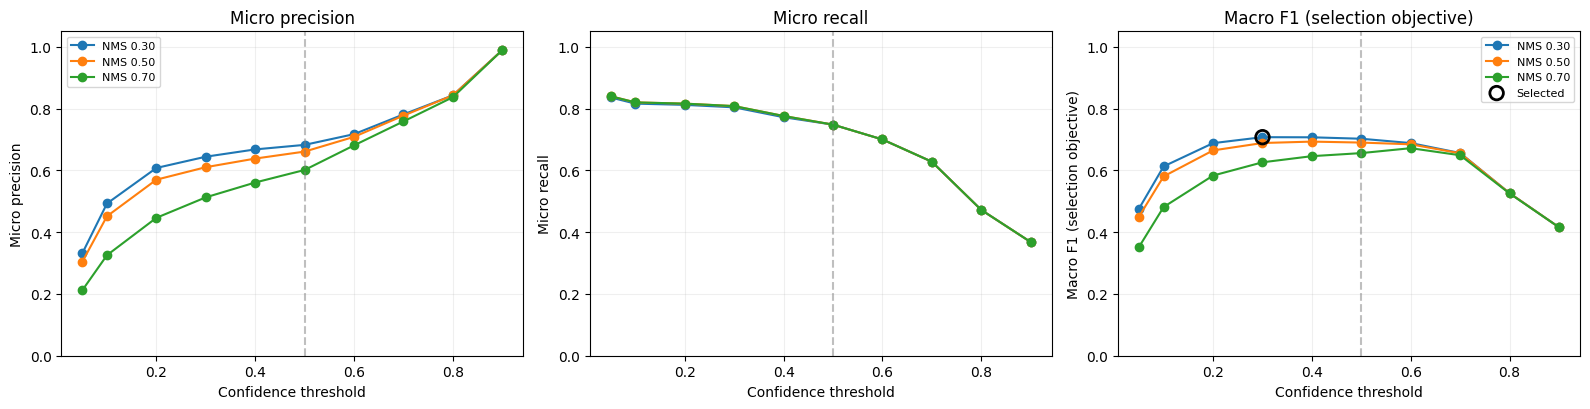

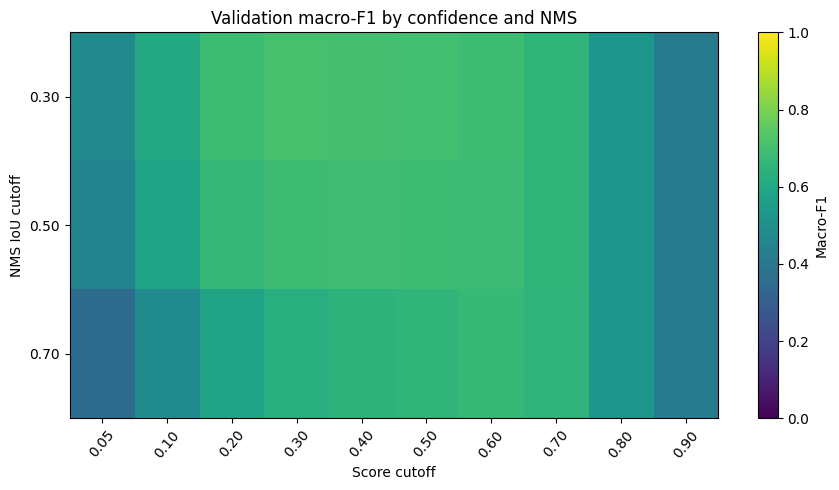

In [13]:
if MODE == 'real':
    fig,axes=plt.subplots(1,3,figsize=(16,4.2))
    for nms,group in grid.groupby('nms'):
        group=group.sort_values('score')
        for ax,col in zip(axes,['micro_precision','micro_recall','macro_f1']):
            ax.plot(group.score,group[col],marker='o',label=f'NMS {nms:.2f}')
    for ax,col,title in zip(axes,['micro_precision','micro_recall','macro_f1'],
                            ['Micro precision','Micro recall','Macro F1 (selection objective)']):
        ax.axvline(BASELINE_SCORE,ls='--',color='gray',alpha=.5)
        ax.set(xlabel='Confidence threshold',ylabel=title,title=title,ylim=(0,1.05));ax.grid(alpha=.2)
    axes[2].scatter([BEST_SCORE],[best_metrics['macro_f1']],s=95,facecolors='none',
                    edgecolors='black',linewidths=2,zorder=5,label='Selected')
    axes[0].legend(fontsize=8);axes[2].legend(fontsize=8)
    fig.tight_layout();fig.savefig(OUTPUT_DIR/'confidence_threshold_curves.png',dpi=170);plt.show()

    fig,ax=plt.subplots(figsize=(9,5))
    heat=grid.pivot(index='nms',columns='score',values='macro_f1').sort_index()
    im=ax.imshow(heat.to_numpy(),aspect='auto',vmin=0,vmax=1,cmap='viridis')
    ax.set_xticks(np.arange(len(heat.columns)),[f'{x:.2f}' for x in heat.columns],rotation=50)
    ax.set_yticks(np.arange(len(heat.index)),[f'{x:.2f}' for x in heat.index])
    ax.set(xlabel='Score cutoff',ylabel='NMS IoU cutoff',title='Validation macro-F1 by confidence and NMS')
    fig.colorbar(im,ax=ax,label='Macro-F1');fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'validation_nms_confidence_heatmap.png',dpi=170);plt.show()

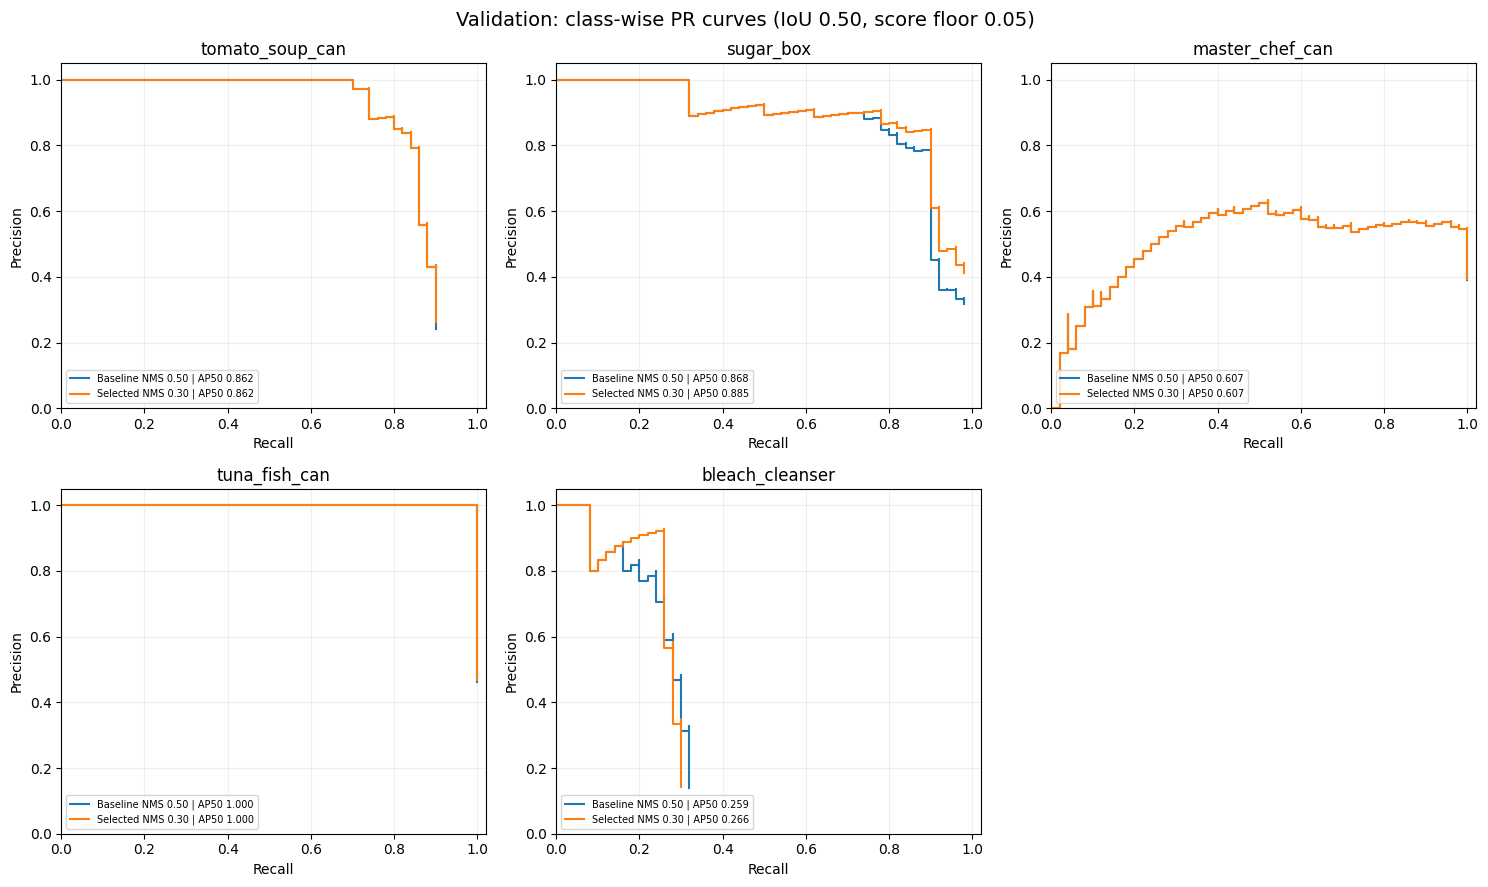

In [14]:
if MODE == 'real':
    fig,axes=plt.subplots(2,3,figsize=(15,9))
    for cls,ax in enumerate(axes.flat[:5],start=1):
        base=match_one_class(BASELINE_PREDS,VAL_TARGETS,cls,AP_FLOOR)
        opt=match_one_class(BEST_PREDS,VAL_TARGETS,cls,AP_FLOOR)
        for matched,label in [(base,f'Baseline NMS {BASELINE_NMS:.2f}'),
                              (opt,f'Selected NMS {BEST_NMS:.2f}')]:
            recall,precision=pr_sequence(matched)
            ax.step(recall,precision,where='post',label=f'{label} | AP50 {ap50_from_matches(matched):.3f}')
        ax.set(title=LABEL_TO_NAME[cls],xlabel='Recall',ylabel='Precision',xlim=(0,1.02),ylim=(0,1.05))
        ax.grid(alpha=.2);ax.legend(fontsize=7,loc='lower left')
    axes.flat[5].axis('off')
    fig.suptitle('Validation: class-wise PR curves (IoU 0.50, score floor 0.05)',fontsize=14)
    fig.tight_layout();fig.savefig(OUTPUT_DIR/'validation_per_class_precision_recall.png',dpi=170);plt.show()

## H. Multiple-object analysis and failure audit (validation only)

A frame is **multi-object** here only if it contains at least two *retained selected-class GT instances*; there can be additional unlabeled YCB objects. Analyze that subset separately from zero/one-target frames. Subgroup *macro* metrics average only over classes with at least one GT instance in that subgroup (so comparisons across groups have different denominators). An apparent false positive can overlap a visible **unselected** YCB object or a dropped selected annotation; flag these as **possible partial-label cases**, without silently excluding them from the primary FP count.

In [15]:
if MODE == 'real':
    VAL_ROWS=FRAME_RECORDS['validation']
    group_metrics=[]
    for group_name,indices in [
        ('at_least_two_selected_gt',[i for i,r in enumerate(VAL_ROWS) if len(r['labels'])>=2]),
        ('zero_or_one_selected_gt',[i for i,r in enumerate(VAL_ROWS) if len(r['labels'])<2]),
    ]:
        if not indices: continue
        truth=[VAL_TARGETS[i] for i in indices]
        for setting,preds,score in [('baseline',BASELINE_PREDS,BASELINE_SCORE),
                                    ('selected',BEST_PREDS,BEST_SCORE)]:
            stats,classes=evaluate_detection([preds[i] for i in indices],truth,score)
            group_metrics.append({'group':group_name,'setting':setting,'frames':len(indices),
                                  **{k:stats[k] for k in ('micro_precision','micro_recall','micro_f1',
                                                         'macro_f1','mAP50','tp','fp','fn')}})
    multi_table=pd.DataFrame(group_metrics)
    display(multi_table.round(3))
    multi_table.to_csv(OUTPUT_DIR/'validation_multi_object_comparison.csv',index=False)

    # One-to-one matching for each frame is identical to global matching restricted to a frame.
    def frame_counts(pred,truth,score):
        counts={'tp':0,'fp':0,'fn':0}
        for cls in range(1,NUM_CLASSES):
            matched=match_one_class([pred],[truth],cls,score)
            for k in counts: counts[k]+=matched[k]
        return counts

    frame_deltas=[]
    for i,r in enumerate(VAL_ROWS):
        b=frame_counts(BASELINE_PREDS[i],VAL_TARGETS[i],BASELINE_SCORE)
        s=frame_counts(BEST_PREDS[i],VAL_TARGETS[i],BEST_SCORE)
        frame_deltas.append({'index':i,'scene_id':r['scene_id'],'im_id':r['im_id'],
                             'selected_gt':len(r['labels']),
                             'baseline_fp':b['fp'],'baseline_fn':b['fn'],
                             'selected_fp':s['fp'],'selected_fn':s['fn'],
                             'error_delta':(s['fp']+s['fn'])-(b['fp']+b['fn'])})
    frame_df=pd.DataFrame(frame_deltas)
    frame_df.to_csv(OUTPUT_DIR/'validation_frame_changes.csv',index=False)
    display(frame_df.sort_values('error_delta').head(8))
    display(frame_df.sort_values('error_delta',ascending=False).head(8))

,group,setting,frames,micro_precision,micro_recall,micro_f1,macro_f1,mAP50,tp,fp,fn
0,at_least_two_selected_gt,baseline,50,0.668,0.685,0.677,0.664,0.747,137,68,63
1,at_least_two_selected_gt,selected,50,0.668,0.755,0.709,0.701,0.753,151,75,49
2,zero_or_one_selected_gt,baseline,50,0.641,1.000,0.781,1.000,1.000,50,28,0
3,zero_or_one_selected_gt,selected,50,0.581,1.000,0.735,1.000,1.000,50,36,0


,index,scene_id,im_id,selected_gt,baseline_fp,baseline_fn,selected_fp,selected_fn,error_delta
92,92,55,1567,4,3,0,1,0,-2
97,97,55,1625,4,3,0,1,0,-2
91,91,55,1543,4,3,0,1,0,-2
56,56,55,454,4,1,2,1,1,-1
61,61,55,563,4,2,2,2,1,-1
58,58,55,526,4,1,2,1,1,-1
57,57,55,512,4,1,2,1,1,-1
59,59,55,530,4,2,3,3,1,-1


,index,scene_id,im_id,selected_gt,baseline_fp,baseline_fn,selected_fp,selected_fn,error_delta
70,70,55,793,4,1,2,3,2,2
34,34,52,575,1,0,0,1,0,1
38,38,52,604,1,0,0,1,0,1
42,42,52,643,1,0,0,1,0,1
40,40,52,625,1,0,0,1,0,1
47,47,52,678,1,0,0,1,0,1
99,99,55,1717,4,0,0,1,0,1
96,96,55,1612,4,0,0,1,0,1


In [16]:
if MODE == 'real':
    def overlap_max(box, possible_boxes):
        if not possible_boxes: return 0.0
        other=torch.tensor(possible_boxes,dtype=torch.float32).reshape(-1,4)
        return float(box_iou(box.float().reshape(1,4),other).max())

    def classify_false_positives(predictions,targets,records,threshold):
        audited=[]
        for image_idx,(pred,gt,record) in enumerate(zip(predictions,targets,records)):
            for cls in range(1,NUM_CLASSES):
                matched=match_one_class([pred],[gt],cls,threshold)
                true_boxes=[pred['boxes'][entry['prediction_index']].tolist()
                            for entry in matched['match_log'] if entry['tp']]
                same_gt=gt['boxes'][gt['labels']==cls].tolist()
                wrong_gt=gt['boxes'][gt['labels']!=cls].tolist()
                ignored_boxes=[v['box'] for v in record['ignored_regions']]
                for entry in matched['match_log']:
                    if entry['tp']: continue
                    box=pred['boxes'][entry['prediction_index']]
                    iou_ignored=overlap_max(box,ignored_boxes)
                    if overlap_max(box,true_boxes)>=.5:
                        reason='possible_duplicate_same_class'
                    elif iou_ignored>=.5:
                        reason='possible_partial_label_overlap'
                    elif overlap_max(box,wrong_gt)>=.5:
                        reason='possible_wrong_class'
                    elif .10<=overlap_max(box,same_gt)<.50:
                        reason='possible_localization_error'
                    else:
                        reason='unmatched_fp_other_or_background'
                    audited.append({'scene_id':record['scene_id'],'im_id':record['im_id'],
                                    'class_name':LABEL_TO_NAME[cls],'score':entry['score'],
                                    'category':reason,'ignored_region_iou':iou_ignored})
        return pd.DataFrame(audited,columns=['scene_id','im_id','class_name','score',
                                             'category','ignored_region_iou'])

    baseline_audit=classify_false_positives(BASELINE_PREDS,VAL_TARGETS,VAL_ROWS,BASELINE_SCORE)
    selected_audit=classify_false_positives(BEST_PREDS,VAL_TARGETS,VAL_ROWS,BEST_SCORE)
    assert len(baseline_audit)==baseline_metrics['fp']
    assert len(selected_audit)==best_metrics['fp']
    for setting,table in [('baseline',baseline_audit),('selected',selected_audit)]:
        table.to_csv(OUTPUT_DIR/f'validation_fp_audit_{setting}.csv',index=False)
        print(f'{setting.upper()} false-positive categories; hypotheses, not verified ground truth:')
        display(table.groupby('category').size().sort_values(ascending=False).rename('count').to_frame())

BASELINE false-positive categories; hypotheses, not verified ground truth:


,count
category,
possible_wrong_class,48
unmatched_fp_other_or_background,32
possible_partial_label_overlap,13
possible_localization_error,3


SELECTED false-positive categories; hypotheses, not verified ground truth:


,count
category,
possible_wrong_class,50
unmatched_fp_other_or_background,34
possible_partial_label_overlap,24
possible_localization_error,3


### H1. Representative frames: original GT / Week 09 baseline / tuned Week 10 settings

Select validation frames by error change **in both directions**, plus multi-object examples. These figures can show improvement **or regression**; don't cherry-pick successes. Omitted-class regions can be overlaid in dashed gray for manual inspection (not used as training GT).

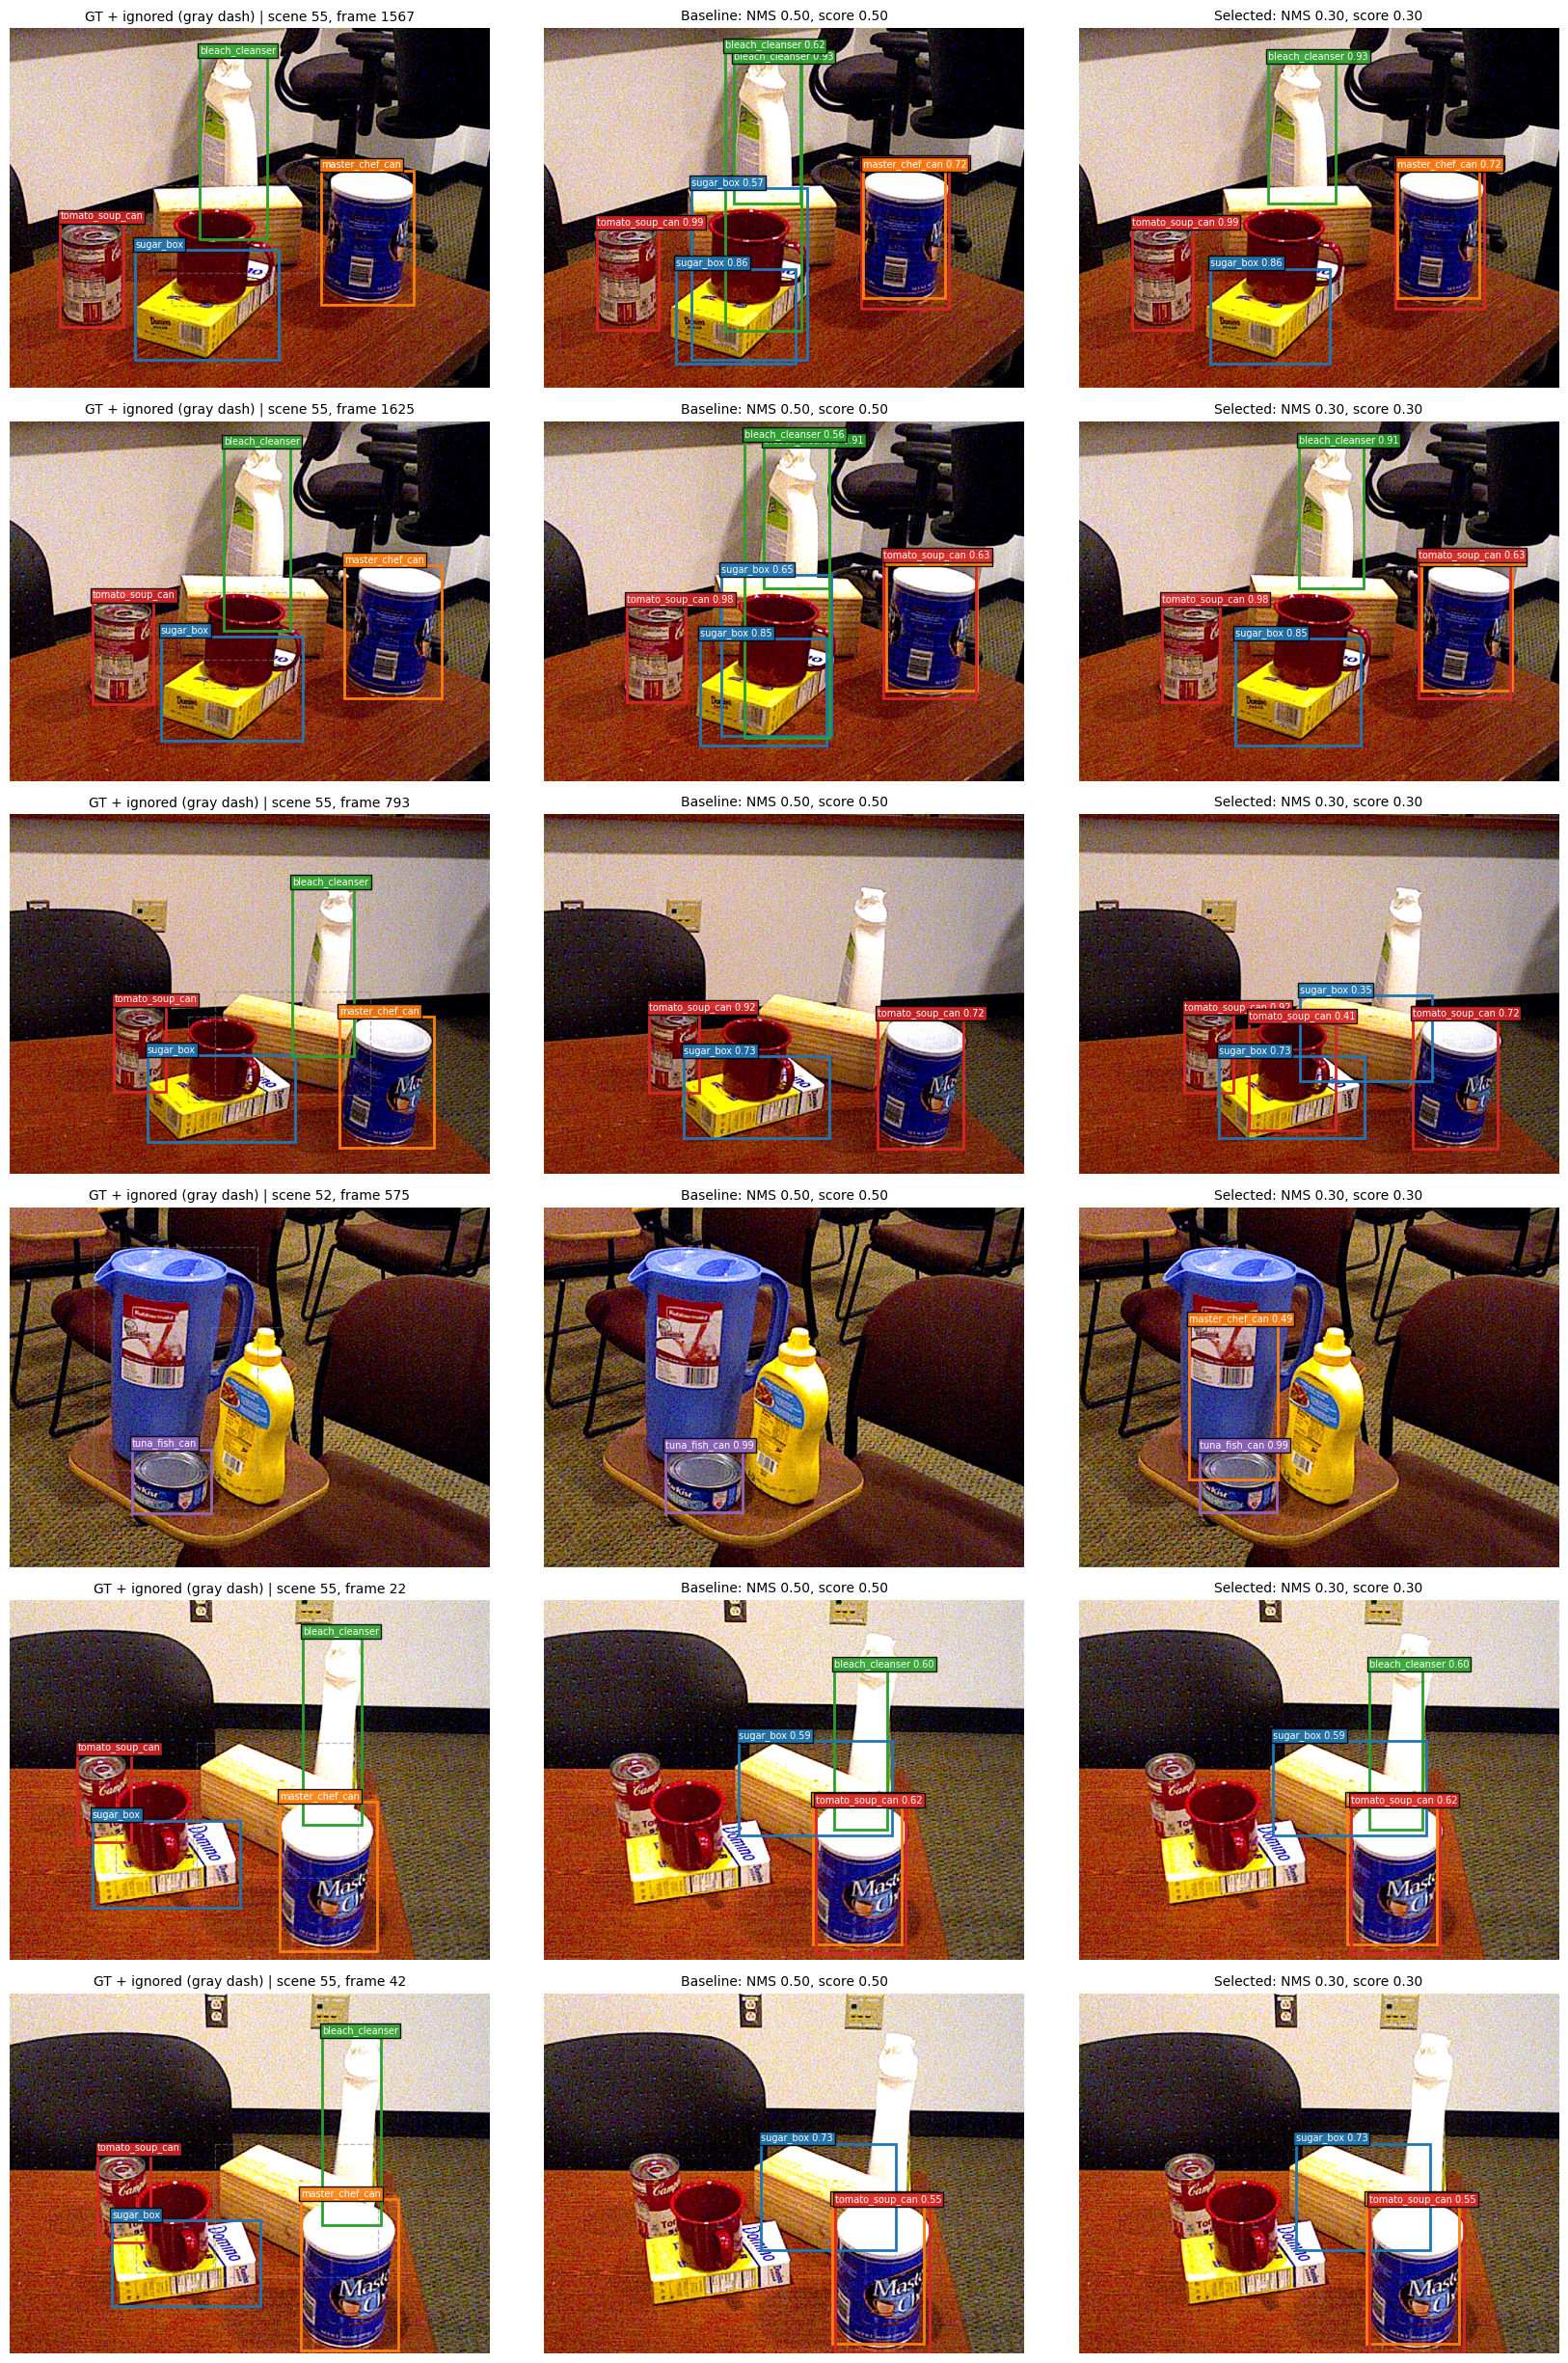

In [17]:
if MODE == 'real':
    def draw_overlay(ax,record,pred=None,threshold=None,show_ignored=False,title=''):
        with Image.open(record['rgb_path']) as raw: image=raw.convert('RGB')
        ax.imshow(image)
        if pred is None:
            boxes=record['boxes'];labels=record['labels'];scores=None
        else:
            mask=pred['scores']>=threshold
            boxes=pred['boxes'][mask].tolist();labels=pred['labels'][mask].tolist()
            scores=pred['scores'][mask].tolist()
        cmap={1:'tab:red',2:'tab:blue',3:'tab:orange',4:'tab:purple',5:'tab:green'}
        for i,(box,label) in enumerate(zip(boxes,labels)):
            x0,y0,x1,y1=map(float,box)
            color=cmap[int(label)]
            ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,linewidth=2,edgecolor=color))
            label_text=LABEL_TO_NAME[int(label)]
            if scores is not None: label_text+=f' {float(scores[i]):.2f}'
            ax.text(x0,max(y0-4,0),label_text,color='white',fontsize=7,
                    bbox=dict(facecolor=color,alpha=.9,pad=1.5))
        if show_ignored:
            for v in record['ignored_regions']:
                x0,y0,x1,y1=v['box']
                ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,
                                       fill=False,lw=1,ls='--',edgecolor='gray',alpha=.55))
        ax.set_title(title,fontsize=10);ax.axis('off')

    def display_comparison(indices,save_name):
        if not indices: return
        fig,axes=plt.subplots(len(indices),3,figsize=(17,4.1*len(indices)),squeeze=False)
        for row,i in enumerate(indices):
            record=VAL_ROWS[i]
            draw_overlay(axes[row,0],record,show_ignored=True,
                         title=f'GT + ignored (gray dash) | scene {record["scene_id"]}, frame {record["im_id"]}')
            draw_overlay(axes[row,1],record,BASELINE_PREDS[i],BASELINE_SCORE,
                         title=f'Baseline: NMS {BASELINE_NMS:.2f}, score {BASELINE_SCORE:.2f}')
            draw_overlay(axes[row,2],record,BEST_PREDS[i],BEST_SCORE,
                         title=f'Selected: NMS {BEST_NMS:.2f}, score {BEST_SCORE:.2f}')
        fig.tight_layout();fig.savefig(OUTPUT_DIR/save_name,dpi=140,bbox_inches='tight');plt.show()

    improved=frame_df.sort_values('error_delta').query('error_delta < 0')['index'].tolist()[:2]
    regressed=frame_df.sort_values('error_delta',ascending=False).query('error_delta > 0')['index'].tolist()[:2]
    multi=frame_df.query('selected_gt >= 2')['index'].tolist()[:2]
    examples=list(dict.fromkeys(improved+regressed+multi))[:6]
    if not examples: examples=list(range(min(3,len(VAL_ROWS))))
    display_comparison(examples,'validation_baseline_vs_selected_examples.png')

## I. YOLO-style detection concepts — conceptual comparison only

The Week 10 specification asks to **study YOLO-style detection**, not to quietly switch the model or claim a YOLO training result.

| Topic | Week 09–10 model: Faster R-CNN | YOLO-style (one-stage) detector |
|---|---|---|
| Pipeline | Backbone/FPN → Region Proposal Network → ROI classifier + box regression | One-stage backbone/neck → dense detection head(s) |
| Output | Boxes, foreground class labels and confidence scores | Boxes + object/class confidence representations (implementation varies by YOLO version) |
| Training | COCO pretrained weights, six-output head fine-tuned on five YCB classes | Would require **separate training**, labels/configuration, and a fair evaluation |
| Duplicates | Torchvision's **class-aware ROI-head NMS** by default | NMS/post-processing often used, exact details are version-dependent |
| Fair comparison | Only adjust thresholds/NMS of same frozen detector | No YOLO speed/accuracy claims without a separately trained model |

**NMS mechanics:** sort overlapping candidate boxes by confidence; keep the highest, suppress *lower-scoring same-class* boxes with IoU above the NMS cutoff. A lower NMS cutoff is more aggressive, potentially improving duplicate precision but removing nearby real objects; a higher cutoff is more permissive. Note that a *confidence threshold* and *NMS IoU threshold* are different quantities. The synthetic unit test earlier demonstrates class-aware NMS. The actual Week 10 sweep changes **the ROI-head NMS before predictions are returned**.

## J. Freeze validation selection, then *optional* repeated-test gate

Test scenes **51/59 were already inspected in prior weeks**. Never use this repeated test to choose Week 10 thresholds. The first real test evaluation writes a gate file; subsequent runs with the same saved settings simply show its saved result. A different configuration requires a new, explicitly identified study, not quietly overwriting this test result.

In [18]:
if MODE == 'real':
    selection={'week':10,'class_ids':SELECTED_IDS,'scene_split':SCENES,
               'source_checkpoint':str(CHECKPOINT_PATH),'checkpoint_sha256':CHECKPOINT_SHA256,
               'checkpoint_epoch':ckpt.get('epoch'),'source':MODEL_ORIGIN,
               'annotation_sha256':ANNOTATION_SHA256,'baseline_nms':BASELINE_NMS,
               'baseline_score':BASELINE_SCORE,'selected_nms':BEST_NMS,
               'selected_score':BEST_SCORE,'iou_threshold':IOU_THRESHOLD,
               'ap_floor':AP_FLOOR,'grid_objective':'validation_macro_f1',
               'validation_metrics_baseline':baseline_metrics,
               'validation_metrics_selected':best_metrics,
               'limitations':['5-class incomplete labels','test scenes previously inspected',
                              'two validation scenes; threshold/NMS selection may overfit',
                              'internal mAP50 is not official COCO/BOP AP']}
    selection_file=OUTPUT_DIR/'frozen_validation_selection.json'
    selection_file.write_text(json.dumps(selection,indent=2),encoding='utf8')
    print('Frozen validation selection saved:',selection_file)

    TEST_METRICS=None
    TEST_CLASSES=None
    test_gate=OUTPUT_DIR/'repeated_test_gate.json'
    if RUN_FINAL_TEST:
        if test_gate.exists():
            saved=json.loads(test_gate.read_text(encoding='utf8'))
            assert saved['selection'] == selection, 'Test already evaluated with DIFFERENT settings. No re-selection on test.'
            TEST_METRICS=saved['metrics']
            TEST_CLASSES=pd.DataFrame(saved['per_class'])
            print('Existing repeated-test result loaded; inference not rerun.')
        else:
            print('Evaluating repeated-scene test ONCE with frozen validation-selected configuration.')
            test_preds=cached_inference('test',BEST_NMS)
            TEST_METRICS,TEST_CLASSES=evaluate_detection(test_preds,targets_for('test'),BEST_SCORE)
            saved={'selection':selection,'metrics':TEST_METRICS,'per_class':TEST_CLASSES.to_dict(orient='records'),
                   'warning':'Repeated historical test scenes; not fresh or official benchmark'}
            test_gate.write_text(json.dumps(saved,indent=2),encoding='utf8')
        display(TEST_CLASSES[['class_name','support','precision','recall','f1','ap50']].round(4))
        print('Repeated test (report only, DO NOT TUNE):',TEST_METRICS)
    else:
        print('Final test deliberately NOT executed. Set RUN_FINAL_TEST=True after validation analysis if needed.')

Frozen validation selection saved: /content/drive/MyDrive/AI_Internship_Group1/Week10/results/frozen_validation_selection.json
Final test deliberately NOT executed. Set RUN_FINAL_TEST=True after validation analysis if needed.


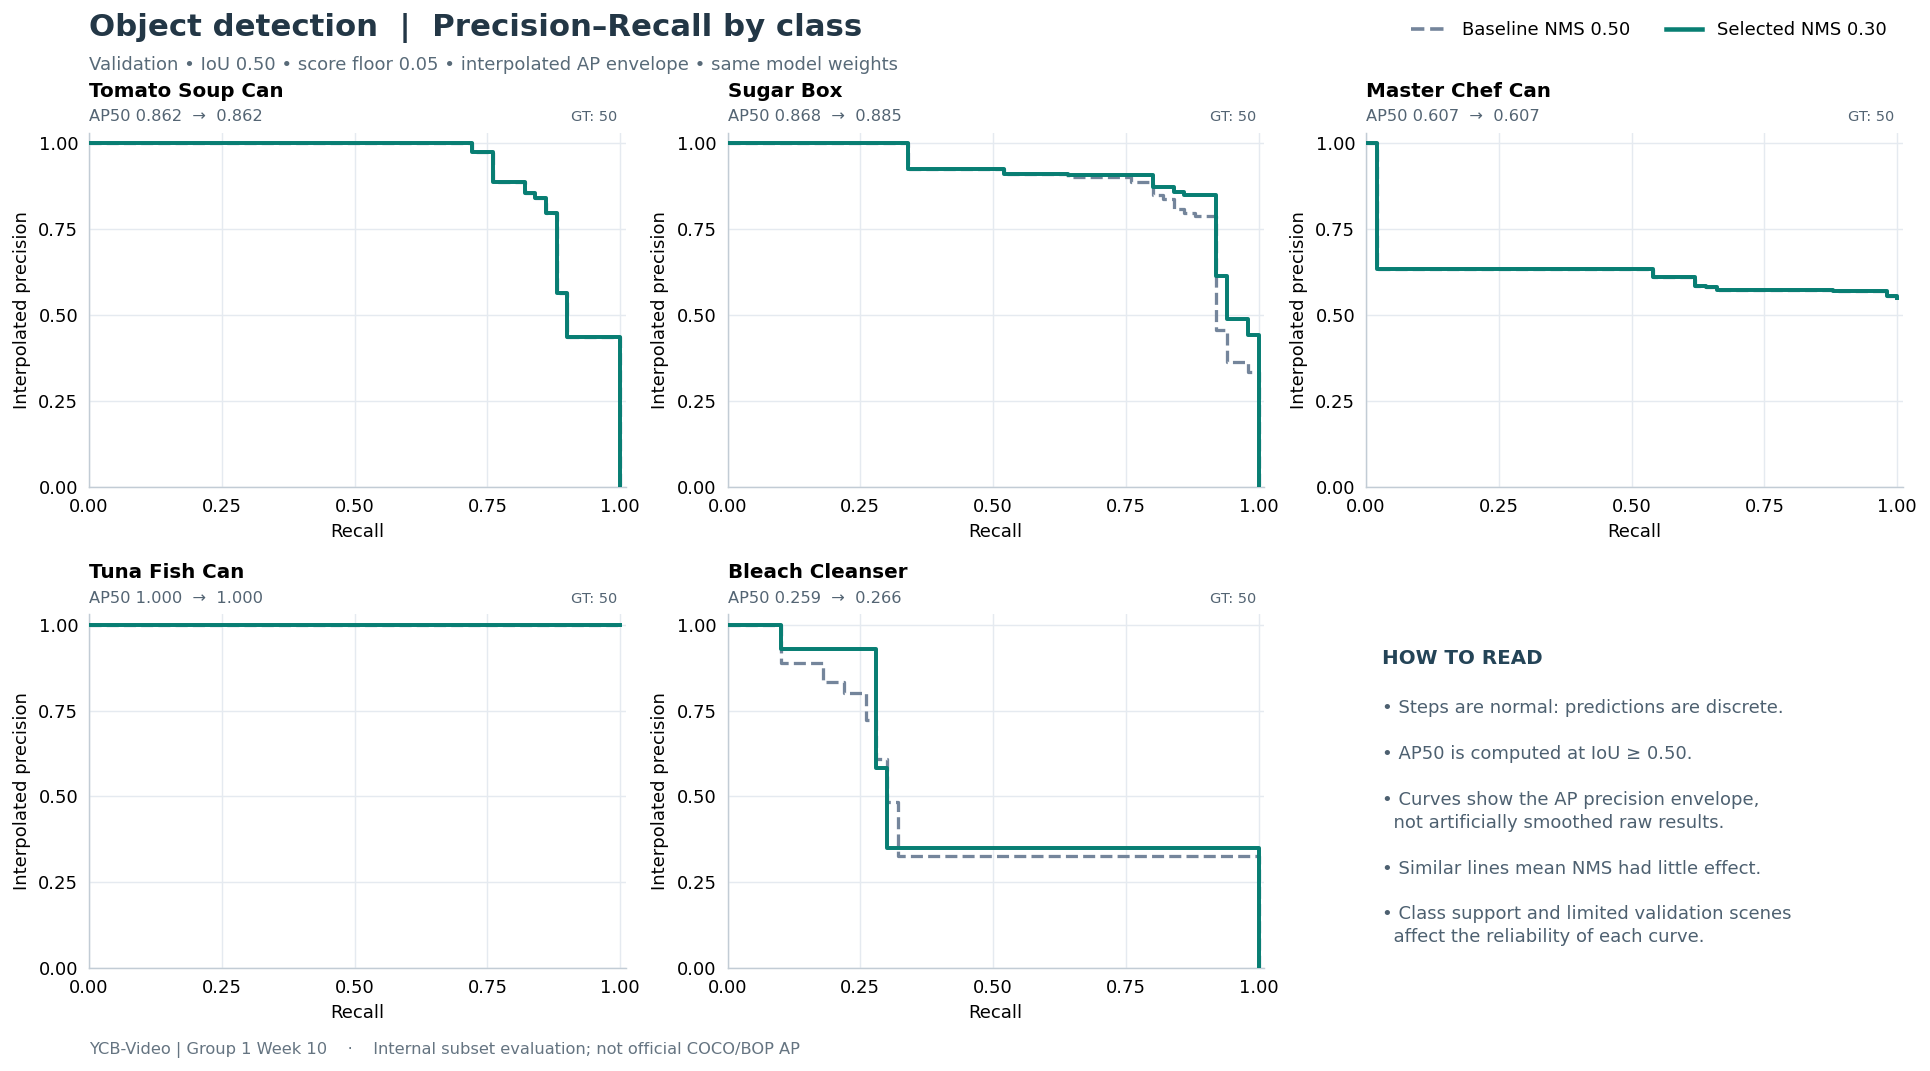

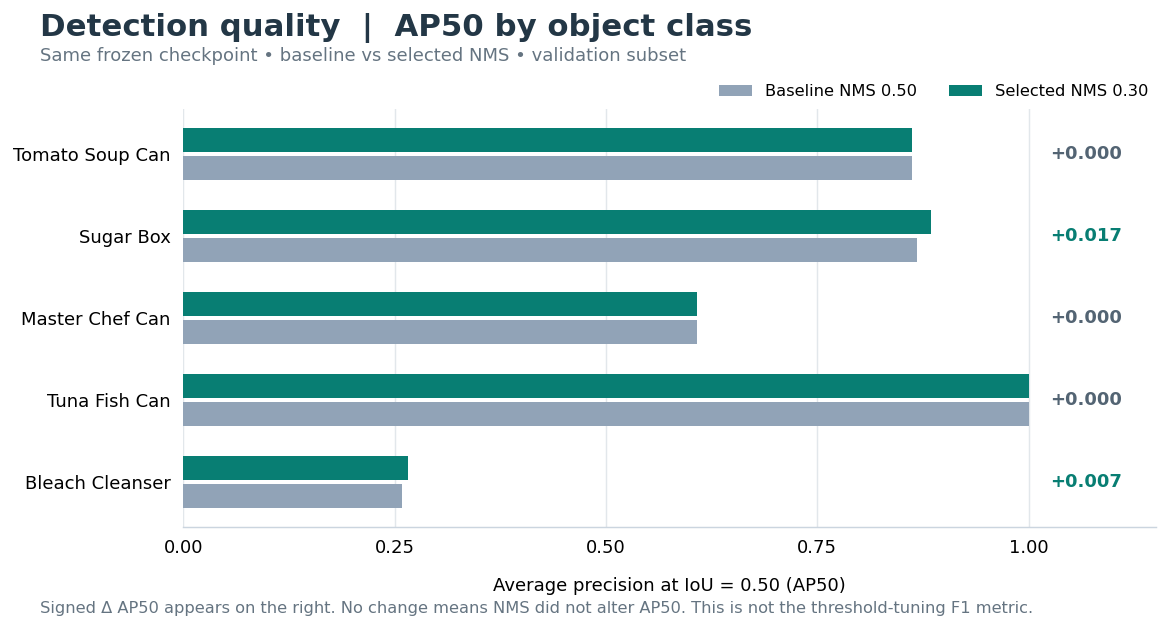

<Figure size 640x480 with 0 Axes>

In [20]:
%run -i /content/week10_plot_refresh_only.py